In [2]:
import pandas as pd
import datasets as DS

DIR = "cleaned_data/STORE1/"

books = DS.loadDataset("books.csv", DIR)
orders = DS.loadDataset("orders.csv", DIR)
users = DS.loadDataset("users.csv", DIR)

### Finding top 5 days by revenue

In [3]:
orders.groupby("date")["paid_price"].sum().sort_values(ascending = False)[:5]

date
2025-08-20    3719.35
2025-09-22    3587.94
2025-09-10    3371.98
2026-01-15    3307.38
2025-09-03    3263.25
Name: paid_price, dtype: float64

In [4]:
import matplotlib.pyplot as plt
import matplotlib.dates as plotdates

earliest = orders["date"].min()
furthest = orders["date"].max()

dates_range = pd.date_range(earliest, furthest, freq="D")
dates_range_list = dates_range.to_list()
daily_revenue_summary = orders.groupby("date")["paid_price"].sum().round(2).sort_index()

daily_revenues = [0 for date in dates_range]
for date, revenue in daily_revenue_summary.items():
    idx_in_range = dates_range_list.index(pd.Timestamp(str(date)))
    daily_revenues[idx_in_range] = revenue



ModuleNotFoundError: No module named 'matplotlib'

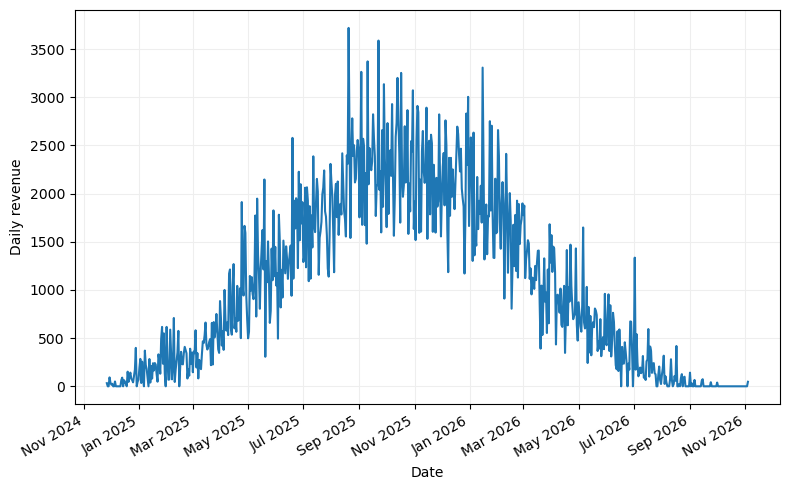

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
plt.grid(color="#eeeeee")
ax.plot(dates_range, daily_revenues)
ax.xaxis.set_major_locator(plotdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(plotdates.DateFormatter("%b %Y"))
plt.xlabel("Date")
plt.ylabel("Daily revenue")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()


In [ ]:
# TOP 5 daily revenue
daily_revenue_summary.sort_values(ascending=False).index[:5]

Index(['2025-08-20', '2025-09-22', '2025-09-10', '2026-01-15', '2025-09-03'], dtype='object', name='date')

### Finding real unique users

In [ ]:
columns = ["name", "address", "phone"]
users.loc[1, columns] == users.loc[2, columns]

name       False
address    False
phone      False
dtype: bool

In [ ]:
import networkx as nx
from itertools import combinations

def countUnique(users:pd.DataFrame):
    g = nx.Graph()
    
    for i in range(users.shape[0]):
        g.add_node(i)
        
    columns = ["name", "address", "phone", "email"]
    users_dict = users[columns].to_dict("records")
    
    def matches(user1, user2) -> int:
        return sum([user1[col] == user2[col] for col in columns])
    
    for id1, id2 in combinations(range(len(users_dict)), 2):
        matching_columns = matches(users_dict[id1], users_dict[id2])
        if matching_columns >= 3:
            g.add_edge(id1, id2)
            
    return nx.number_connected_components(g)

countUnique(users)

3221

In [ ]:
users["id"]

0       50033
1       49617
2       47571
3       47967
4       49031
        ...  
3389    47422
3390    50022
3391    49559
3392    49501
3393    47760
Name: id, Length: 3394, dtype: int64

In [ ]:
from networkx.utils.union_find import UnionFind

def uniqueUsers(users:pd.DataFrame):
    users = users.sort_values(by="id").reset_index(drop=True)
    uf = UnionFind(users["id"])
    users_dict = users.to_dict("records")       # main speed up
    
    columns = ["name", "address", "phone"]

    def matches(user1, user2) -> int:
        return sum([user1[col] == user2[col] for col in columns])
        
    for i in range(len(users_dict)):
        for j in range(i + 1, len(users_dict)):
            if matches(users_dict[i], users_dict[j]) >= 2:
                uf.union(users_dict[i]["id"], users_dict[j]["id"])
                
    return list(uf.to_sets())

all_unique_users = uniqueUsers(users)
len(all_unique_users)

3221

### Find how many unique sets of authors there are

In [22]:
books["author"].isna().sum()

np.int64(0)

In [23]:
len(books["author"].unique()) # but what if some books are written by "Paul, John" and some by "John, Paul"?

377

In [24]:
def sortAuthors(authors:str) -> str:
    return ", ".join(sorted([author.strip() for author in authors.split(",")]))
books["author"] = books["author"].apply(sortAuthors)
len(books["author"].unique())

324

### Find the most popular author by sold book count(set)

In [25]:
sold_book_count = orders.groupby("book_id")["quantity"].sum()
sold_book_count.sort_index()

book_id
22483    20
22484    25
22485    11
22486    27
22487    14
         ..
23227    15
23228    36
23229    18
23230    10
23231    19
Name: quantity, Length: 749, dtype: int64

In [26]:
sold_book_quantity = books[["id", "author"]].merge(sold_book_count, how="inner", left_on="id", right_index=True)
sold_book_quantity[["author", "quantity"]].groupby("author").sum().sort_values(by="quantity", ascending=False)

,quantity
author,
"Darron Ernser, Miss Lorina Kertzmann",173
Ethan Cronin,144
Ali Doyle,138
Aida Macejkovic PhD,127
"Ms. Shanice Feeney, Stephnie Feest",126
...,...
"Gilberto Lehner, Kent Cremin, Randi Williamson",12
Natalie Schuster,10
Francine Grant,10


### Find the top customer by total spending
List all `user_id` values for the possible different addresses phone e-mail or aliases

In [27]:
top_customers = orders[["user_id", "paid_price"]].groupby("user_id", as_index=False).sum().sort_values("paid_price", ascending=False)
top_customers

,user_id,paid_price
1387,48267,1113.65
1350,48227,1065.75
1416,48296,955.85
1922,48822,941.95
1343,48219,901.15
...,...,...
2206,49120,16.00
2717,49654,15.99
377,47204,15.00
1281,48154,14.99


In [28]:
all_unique_users[:5]

[{46809}, {46810}, {46811}, {46812, 47642}, {46813}]

In [29]:
def uniqueUsersSum(prices:pd.DataFrame):
    all_prices = [0 for u in all_unique_users]
    
    def uniqueUserIndex(user_id:int) -> int:
        for i in range(len(all_unique_users)):
            if user_id in all_unique_users[i]:
                return i
        return -1
            
    unique_users_map = {user_id: uniqueUserIndex(user_id) for user_id in prices["user_id"]}
    
    def add_price(user_id:int):
        all_prices[unique_users_map[user_id]] += prices[prices["user_id"] == user_id]["paid_price"].to_list()[0]
        
    prices["user_id"].apply(lambda p: add_price(p))
    return pd.DataFrame({"user_id": all_unique_users, "paid_price": all_prices})

top_unique_customers = uniqueUsersSum(top_customers).sort_values("paid_price", ascending=False)


In [30]:
top_unique_customers[:1]

,user_id,paid_price
1377,"{48227, 48439}",1489.7
